In [1]:
from matplotlib import font_manager
font_path = '/home/t/tomoyuki-mano1/fonts/arial.ttf'
font_manager.fontManager.addfont(font_path)

import matplotlib as mpl
mpl.rcParams.update({
    'font.size': 20,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42})

### Make temporary directory

In [2]:
import os, random, string

In [3]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_IPMFIJRFXMTL


### Main

In [6]:
from matplotlib import pyplot as plt
import numpy as np
from skimage.io import imread, imsave
import h5py
from glob import glob

In [7]:
rootdir = "/bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20241018_rec11"

### template image

In [8]:
template_denoised = imread(os.path.join(rootdir, "run1/mcorr_nonrigid/QC/QC_denoised/template.tif"))
template_raw = imread(os.path.join(rootdir, "run1/mcorr_nonrigid/QC/QC_raw/template.tif"))
template_corrected = imread(os.path.join(rootdir, "run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif"))

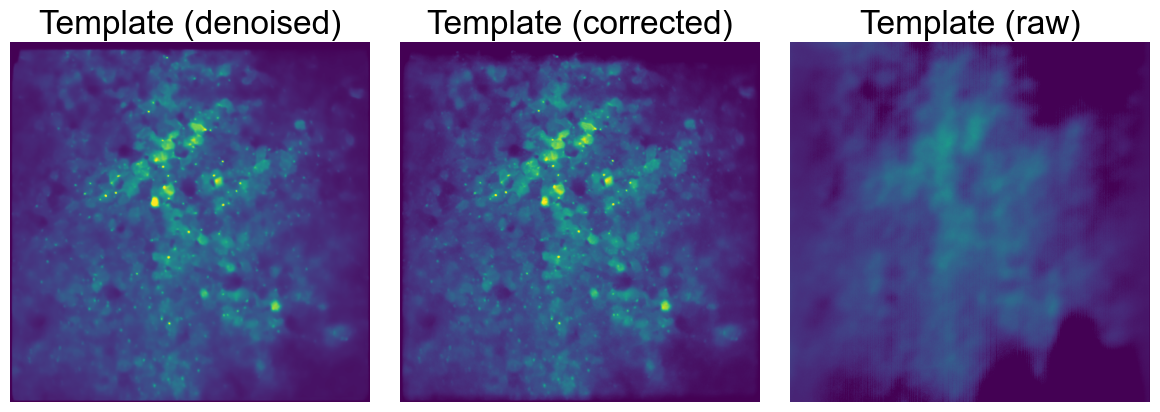

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(12,8))
axs[0].imshow(template_denoised, vmin=10, vmax=1500)
axs[0].set_title("Template (denoised)")
axs[1].imshow(template_corrected, vmin=10, vmax=1500)
axs[1].set_title("Template (corrected)")
axs[2].imshow(template_raw, vmin=10, vmax=1500)
axs[2].set_title("Template (raw)")
for i in range(3):
    axs[i].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "templates.pdf"))
plt.show()

### Plot drift trace

In [10]:
rigid_shifts = np.load(os.path.join(rootdir, "run1/mcorr_rigid", "shifts_rig.npy"))
x_shifts = np.load(os.path.join(rootdir, "run1/mcorr_nonrigid", "x_shifts_els.npy"))
y_shifts = np.load(os.path.join(rootdir, "run1/mcorr_nonrigid", "y_shifts_els.npy"))

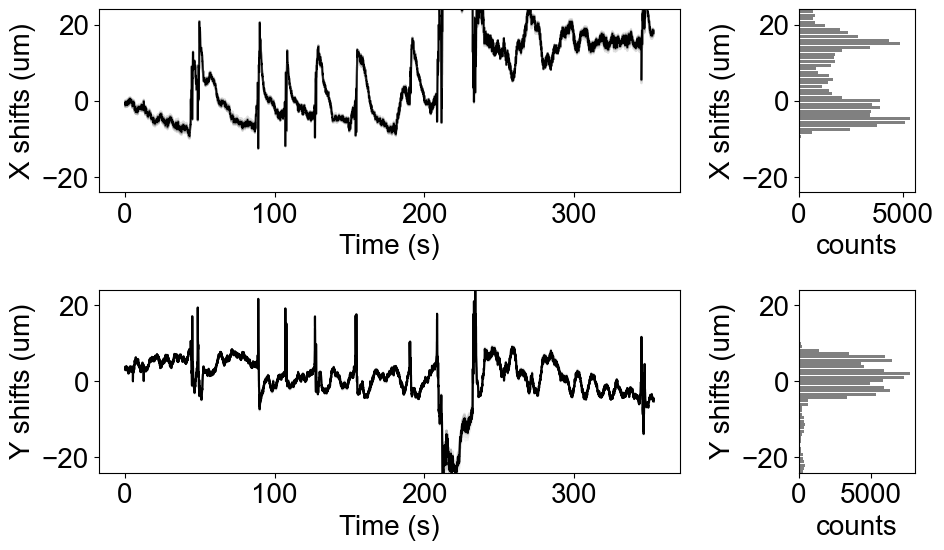

X shift: Mean = 7.105495909926471, STD = 11.3179616168061
Y shift: Mean = 0.4313341452205884, STD = 5.876937129125076


In [11]:
fig, axs = plt.subplots(2, 2, figsize = (250/25.4,150/25.4), gridspec_kw={'width_ratios': [5, 1]})

# 1 pixel = 0.52 um
xs = (rigid_shifts[30:-30, 0] + x_shifts.T).T * 0.52
ys = (rigid_shifts[30:-30, 1] + y_shifts.T).T * 0.52
# Frequency = 15.4 Hz
t = 1/15.4 * np.arange(xs.shape[0])

ax0 = axs[0][0]
for i in range(x_shifts.shape[1]):
    ax0.plot(t, xs[:, i], color="gray", alpha=0.25)
ax0.plot(t, xs.mean(axis=1), color="k", lw=1)
ax0.set_ylabel('X shifts (um)')
ax0.set_xlabel("Time (s)")
ax0.set_ylim([-24,24])

ax1 = axs[0][1]
h, bin_edges = np.histogram(xs.ravel(), bins=64)
bins = (bin_edges[:-1] + bin_edges[1:])/2
ax1.barh(bins, h, color="gray")
ax1.set_ylabel('X shifts (um)')
ax1.set_xlabel('counts')
ax1.set_ylim([-24,24])

ax2 = axs[1,0]
for i in range(ys.shape[1]):
    ax2.plot(t, ys[:, i], color="gray", alpha=0.1)
ax2.plot(t, ys.mean(axis=1), color="k")
ax2.set_ylabel('Y shifts (um)')
ax2.set_xlabel("Time (s)")
ax2.set_ylim([-24,24])

ax3 = axs[1][1]
h, bin_edges = np.histogram(ys.ravel(), bins=64)
bins = (bin_edges[:-1] + bin_edges[1:])/2
ax3.barh(bins, h, color="gray")
ax3.set_ylabel('Y shifts (um)')
ax3.set_xlabel('counts')
ax3.set_ylim([-24,24])

plt.tight_layout()
plt.savefig(os.path.join(tmpdir, "drift_trace.pdf"))
plt.show()

print(f"X shift: Mean = {xs.ravel().mean()}, STD = {xs.ravel().std()}")
print(f"Y shift: Mean = {ys.ravel().mean()}, STD = {ys.ravel().std()}")

### Find the block where the movement was smallest

In [12]:
shifts = np.power(xs.mean(axis=1), 2) + np.power(ys.mean(axis=1), 2)
window_size = 200
running_avg = np.convolve(shifts, np.ones(window_size)/window_size, mode='same')
min_frame = running_avg.argmin()

0


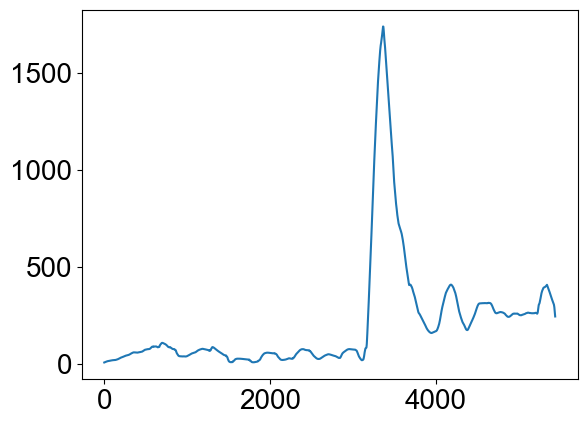

In [13]:
plt.plot(running_avg)
print(min_frame)

In [14]:
with h5py.File(os.path.join(rootdir, "run1/mcorr_nonrigid_denoised/denoised.h5"), "r") as hf:
    img = hf["data"][min_frame-50+60:min_frame+50+60]
    template = img.mean(axis=0)
    template = np.clip(template, 0, 65535).astype("uint16")

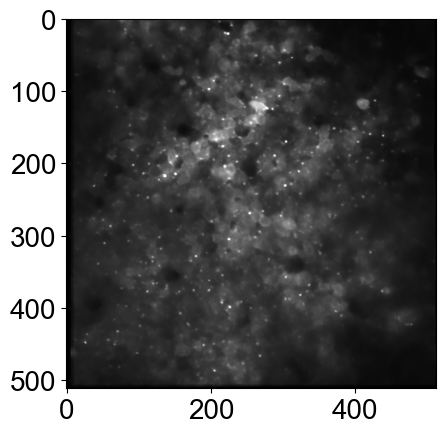

In [15]:
plt.imshow(template, vmin=10, vmax=1500, cmap="gray")

In [16]:
imsave(os.path.join(tmpdir, "new_template.tif"), template, check_contrast=False)

### Correlation between the template and each frame

In [17]:
r1 = np.load(os.path.join(rootdir, "run1/mcorr_nonrigid/QC/QC_denoised/correlations.npy"))
r2 = np.load(os.path.join(rootdir, "run1/mcorr_nonrigid/QC/QC_nonrigid/correlations.npy"))
r3 = np.load(os.path.join(rootdir, "run1/mcorr_nonrigid/QC/QC_raw/correlations.npy"))

In [18]:
# Pad zeros
r1 = np.pad(r1, (60,60), mode='constant', constant_values=0)
r2 = np.pad(r2, (30,30), mode='constant', constant_values=0)

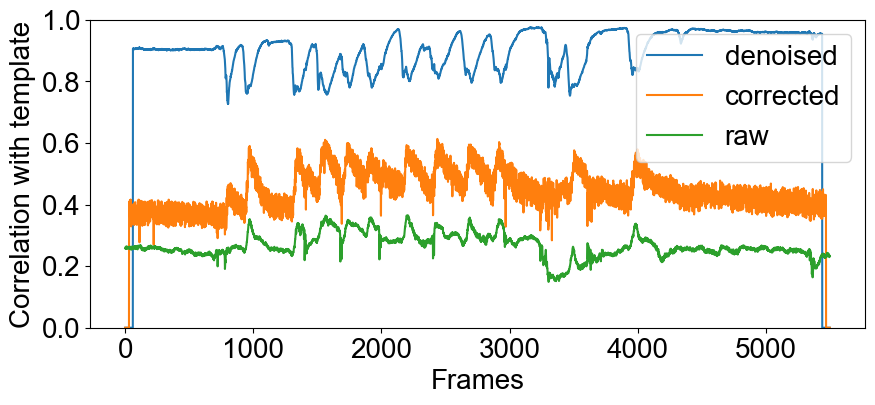

In [19]:
fig, ax = plt.subplots(figsize = (10,4))
ax.plot(r1, label="denoised")
ax.plot(r2, label="corrected")
ax.plot(r3, label="raw")
ax.set_ylabel('Correlation with template')
ax.set_xlabel("Frames")
ax.set_ylim([0, 1])
plt.legend()
plt.show()

In [20]:
from scipy import ndimage as ndi

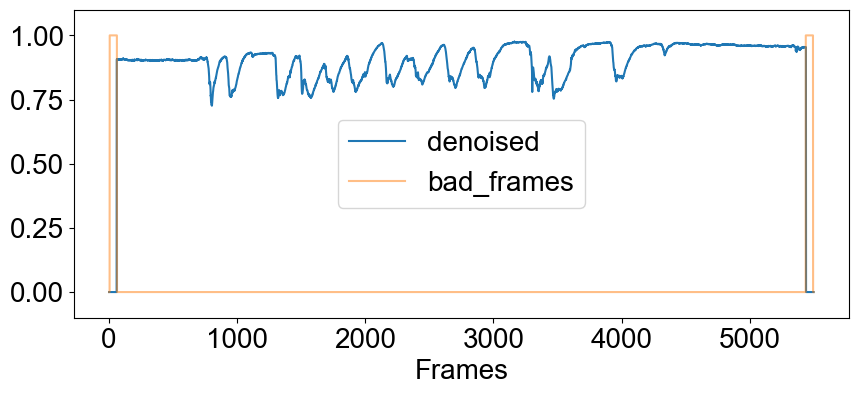

In [23]:
bad_frames = r1 < 0.70
# remove specle-like noise less than 1 frames
bad_frames = ndi.binary_opening(bad_frames, structure=np.ones(3))
# close gaps caused by noise
bad_frames = ndi.binary_closing(bad_frames, structure=np.ones(15))
# enlarge a little bit before and after
bad_frames = ndi.binary_dilation(bad_frames, structure=np.ones(5))

fig, ax = plt.subplots(figsize = (10,4))
ax.plot(r1, label="denoised")
ax.plot(bad_frames, label="bad_frames", alpha=0.5)
ax.set_xlabel("Frames")
ax.set_ylim([-0.1, 1.1])
plt.legend()
plt.show()

In [24]:
np.save(os.path.join(tmpdir, "bad_frames.npy"), bad_frames)

### Save to bucket

In [25]:
savedir = os.path.join(rootdir, "run1/mcorr_nonrigid/QC")
print(f"cp -r {tmpdir}/* {savedir}")

cp -r /flash/ReiterU/tmp/tomo_IPMFIJRFXMTL/* /bucket/ReiterU/OLdev/analysis/20250416_IGL_waves/20241018_rec11/run1/mcorr_nonrigid/QC
